# Pass 14

## Problem Definition


Business problem: estimate a house’s sale price.

Data science problem: supervised regression, since we know the real prices and the target is a number.

## Data Collection/Sources


In [1]:
#import from IPython.display import Image
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns

from sklearn import datasets, metrics, model_selection
from sklearn import model_selection
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import cross_val_score
import statsmodels.api as sm
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso

In [2]:
# file name
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'

In [3]:
#load all the data
house_df= pd.read_csv(url)


In [4]:
# find all text columns (object)
obj_columns = house_df.select_dtypes(include=['object']).columns.tolist()
obj_columns

['MS Zoning',
 'Street',
 'Alley',
 'Lot Shape',
 'Land Contour',
 'Utilities',
 'Lot Config',
 'Land Slope',
 'Neighborhood',
 'Condition 1',
 'Condition 2',
 'Bldg Type',
 'House Style',
 'Roof Style',
 'Roof Matl',
 'Exterior 1st',
 'Exterior 2nd',
 'Mas Vnr Type',
 'Exter Qual',
 'Exter Cond',
 'Foundation',
 'Bsmt Qual',
 'Bsmt Cond',
 'Bsmt Exposure',
 'BsmtFin Type 1',
 'BsmtFin Type 2',
 'Heating',
 'Heating QC',
 'Central Air',
 'Electrical',
 'Kitchen Qual',
 'Functional',
 'Fireplace Qu',
 'Garage Type',
 'Garage Finish',
 'Garage Qual',
 'Garage Cond',
 'Paved Drive',
 'Pool QC',
 'Fence',
 'Misc Feature',
 'Sale Type',
 'Sale Condition']

In [5]:
# this now includes object AND "SalePrice" columns
house_df_target_objects = house_df[obj_columns + ['SalePrice']].copy()

In [6]:
# Columns data types
house_df_target_objects.dtypes.sort_values()


,0
SalePrice,int64
BsmtFin Type 1,object
BsmtFin Type 2,object
Heating,object
Heating QC,object
Central Air,object
Electrical,object
Kitchen Qual,object
Functional,object
Bsmt Exposure,object


In [7]:
# look at first and last few rows
house_df_target_objects.head()


,MS Zoning,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,...,Garage Finish,Garage Qual,Garage Cond,Paved Drive,Pool QC,Fence,Misc Feature,Sale Type,Sale Condition,SalePrice
0,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,Feedr,...,Unf,TA,TA,N,NaN,MnPrv,NaN,WD,Normal,115400
1,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,Norm,...,Unf,TA,TA,Y,NaN,NaN,Shed,WD,Normal,90000
2,RM,Pave,NaN,Reg,Bnk,AllPub,Inside,Gtl,IDOTRR,Norm,...,Unf,TA,TA,P,NaN,NaN,NaN,WD,Normal,141000
3,FV,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Somerst,Norm,...,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal,254000
4,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,SWISU,Feedr,...,RFn,TA,TA,Y,NaN,MnPrv,NaN,WD,Normal,155000


In [8]:
# look at the last few rows
house_df_target_objects.tail()

,MS Zoning,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,...,Garage Finish,Garage Qual,Garage Cond,Paved Drive,Pool QC,Fence,Misc Feature,Sale Type,Sale Condition,SalePrice
2632,RM,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,BrkSide,Norm,...,Unf,TA,TA,Y,NaN,MnPrv,Shed,WD,Normal,114500
2633,RL,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,SawyerW,Feedr,...,Unf,TA,TA,Y,NaN,NaN,NaN,WD,Normal,162000
2634,RL,Pave,NaN,IR1,Lvl,AllPub,CulDSac,Gtl,Greens,Norm,...,Fin,TA,TA,Y,NaN,NaN,NaN,WD,Normal,211500
2635,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,Norm,...,RFn,TA,TA,Y,NaN,MnPrv,NaN,WD,Normal,165000
2636,RL,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,Gilbert,RRAn,...,Fin,TA,TA,Y,NaN,NaN,NaN,WD,Normal,225000


In [9]:
# look at shape and size

print(house_df_target_objects.shape)
print(house_df_target_objects.size)


(2637, 44)
116028


In [10]:
# display meta data (info)
house_df_target_objects.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2637 entries, 0 to 2636
Data columns (total 44 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   MS Zoning       2637 non-null   object
 1   Street          2637 non-null   object
 2   Alley           180 non-null    object
 3   Lot Shape       2637 non-null   object
 4   Land Contour    2637 non-null   object
 5   Utilities       2637 non-null   object
 6   Lot Config      2637 non-null   object
 7   Land Slope      2637 non-null   object
 8   Neighborhood    2637 non-null   object
 9   Condition 1     2637 non-null   object
 10  Condition 2     2637 non-null   object
 11  Bldg Type       2637 non-null   object
 12  House Style     2637 non-null   object
 13  Roof Style      2637 non-null   object
 14  Roof Matl       2637 non-null   object
 15  Exterior 1st    2637 non-null   object
 16  Exterior 2nd    2637 non-null   object
 17  Mas Vnr Type    1030 non-null   object
 18  Exter Qu

In [11]:
# display summary statistics
house_df_target_objects.describe(include='object')



,MS Zoning,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,...,Garage Type,Garage Finish,Garage Qual,Garage Cond,Paved Drive,Pool QC,Fence,Misc Feature,Sale Type,Sale Condition
count,2637,2637,180,2637,2637,2637,2637,2637,2637,2637,...,2492,2490,2490,2490,2637,11,528,96,2637,2637
unique,7,2,2,4,4,3,5,3,28,9,...,6,3,5,5,3,4,4,4,10,6
top,RL,Pave,Grvl,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,...,Attchd,Unf,TA,TA,Y,Gd,MnPrv,Shed,WD,Normal
freq,2043,2625,111,1662,2365,2634,1924,2511,397,2273,...,1563,1106,2356,2400,2395,4,306,87,2286,2166


In [12]:
# look for how the often a value appears
house_df['SalePrice'].value_counts(dropna=False)


,count
SalePrice,
140000,31
135000,30
130000,28
155000,24
160000,22
...,...
160200,1
174190,1
415298,1


In [13]:
# look for nulls in target and features
house_df_target_objects.isnull().sum().sort_values(ascending=False)

,0
Pool QC,2626
Misc Feature,2541
Alley,2457
Fence,2109
Mas Vnr Type,1607
Fireplace Qu,1284
Garage Qual,147
Garage Finish,147
Garage Cond,147
Garage Type,145


## Data Cleaning


### Backup 1

In [14]:
# make backup
house_df_target_objects_backup = house_df_target_objects.copy()

In [15]:
# restore from backup
house_df_target_objects = house_df_target_objects_backup.copy()

### Address any rows with nulls

- If the number of nulls in a column is low, it would be easiest to drop the row.
- If the number of nulls in a column is high, it would be easiest to drop the column.
- If the number of nulls in a column is between the low and high, one should impute values for the nulls.

In [16]:
# look for nulls in feature in percentage
house_df_target_objects.isnull().mean() * 100

,0
MS Zoning,0.000000
Street,0.000000
Alley,93.174061
Lot Shape,0.000000
Land Contour,0.000000
Utilities,0.000000
Lot Config,0.000000
Land Slope,0.000000
Neighborhood,0.000000
Condition 1,0.000000


### Impute

In [17]:
# For text columns, a null usually means "this house doesn't have it"
# (no pool, no alley, no garage). So fill with the word 'None'.
house_df_target_objects = house_df_target_objects.fillna('None')


In [18]:
#check that null are removed from object
house_df_target_objects.isnull().sum()

,0
MS Zoning,0
Street,0
Alley,0
Lot Shape,0
Land Contour,0
Utilities,0
Lot Config,0
Land Slope,0
Neighborhood,0
Condition 1,0


## Exploratory Data Analysis


Linear Regression has two requirements:
1. the features are correlated with the target
1. the features are not correlated with each other

In [19]:
# How many categories does each column have?
house_df_target_objects.nunique().sort_values()

,0
Street,2
Central Air,2
Land Slope,3
Alley,3
Utilities,3
Paved Drive,3
Exter Qual,4
Land Contour,4
Kitchen Qual,4
Lot Shape,4


In [20]:
# Average price for each category in one feature
house_df_target_objects.groupby('Neighborhood')['SalePrice'].mean().sort_values()

,SalePrice
Neighborhood,
MeadowV,96271.764706
IDOTRR,101837.142857
BrDale,106919.642857
OldTown,123955.233945
BrkSide,124520.876289
Edwards,127880.154762
SWISU,135271.659091
Landmrk,137000.000000
Sawyer,137046.123188


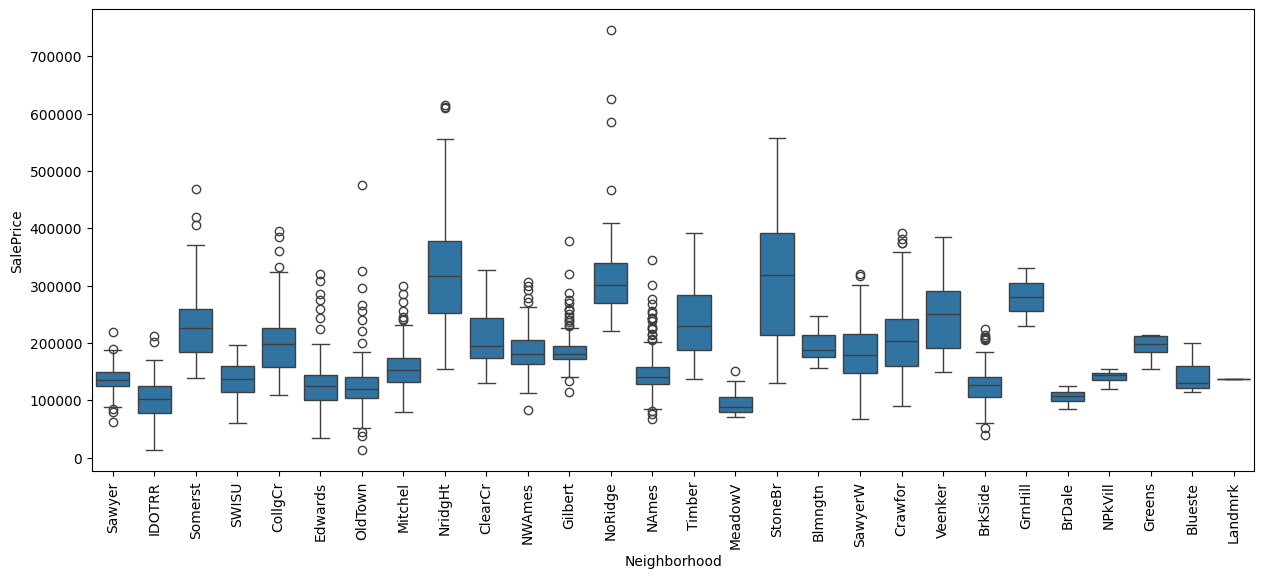

In [21]:
# Box plot: price spread for each category
# Boxes at very different heights = the feature is linked to price
# Boxes all at the same height = the feature doesn't tell you much
plt.figure(figsize=(15, 6))
sns.boxplot(data=house_df_target_objects, x='Neighborhood', y='SalePrice')
plt.xticks(rotation=90)
plt.show()

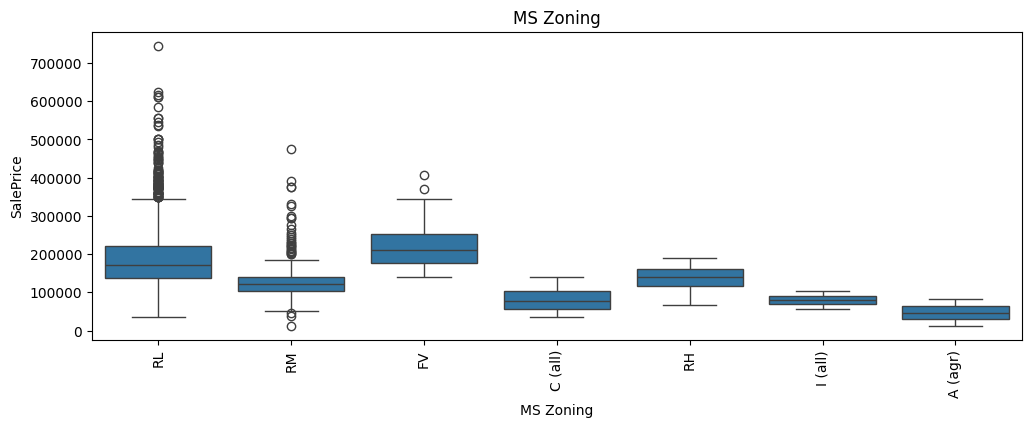

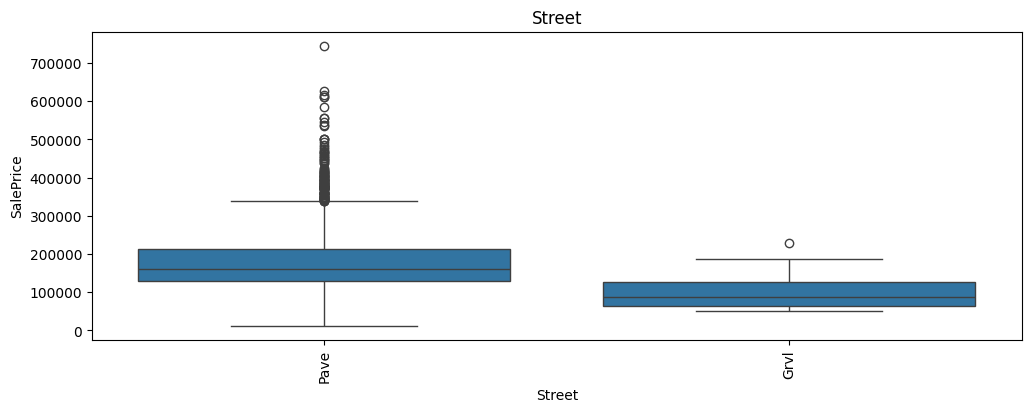

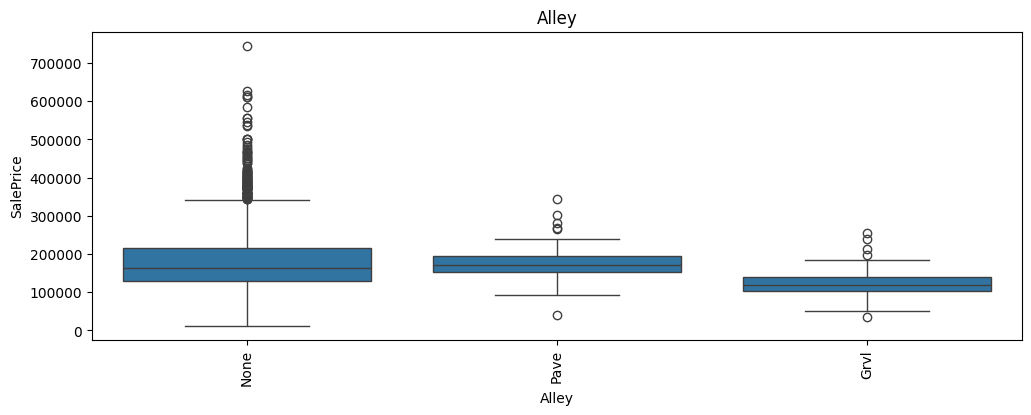

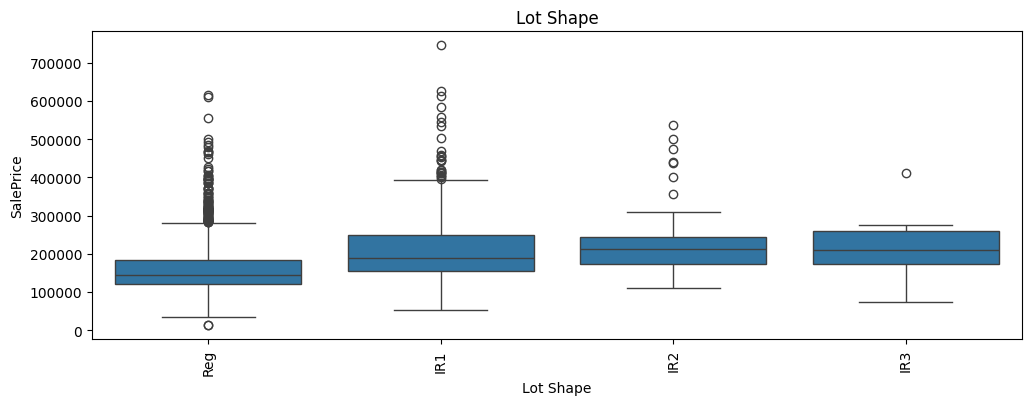

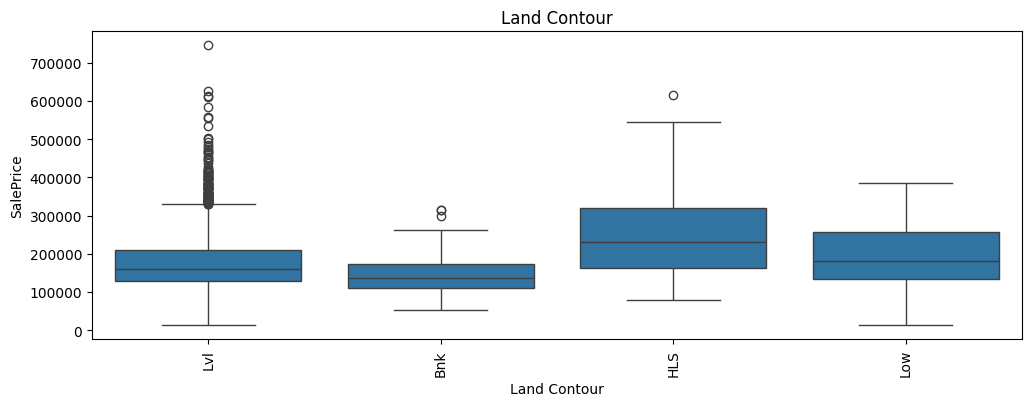

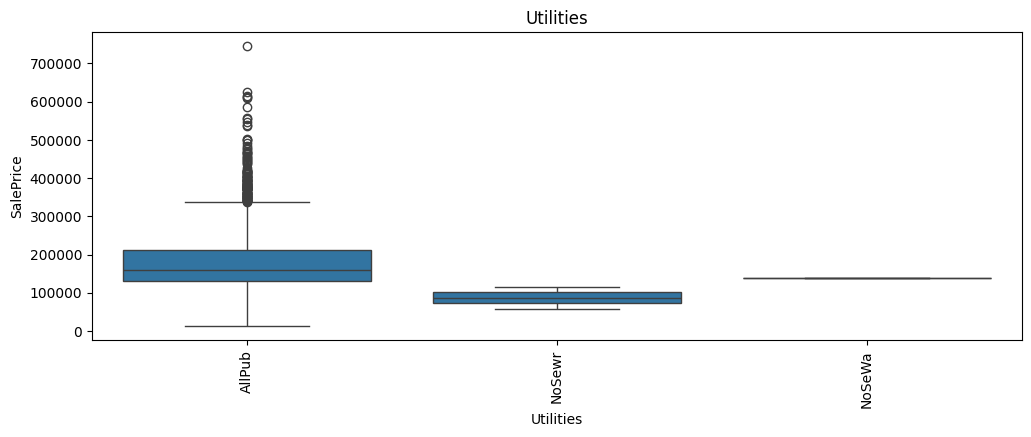

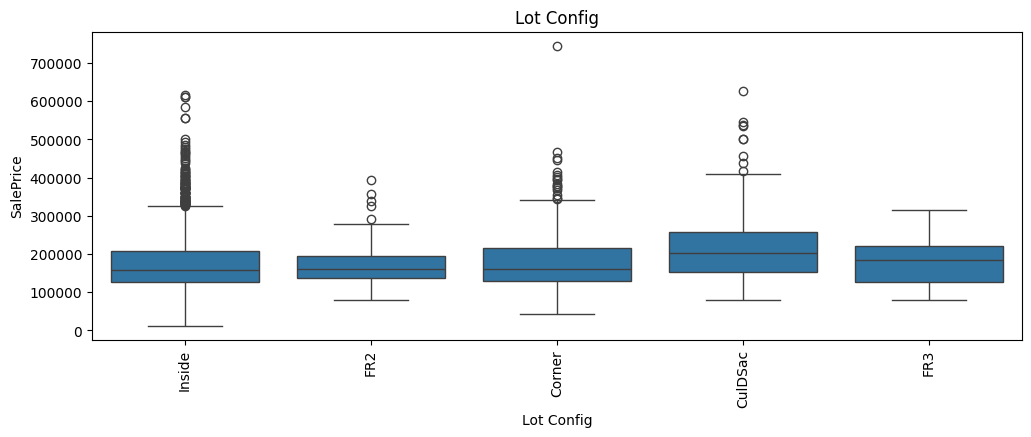

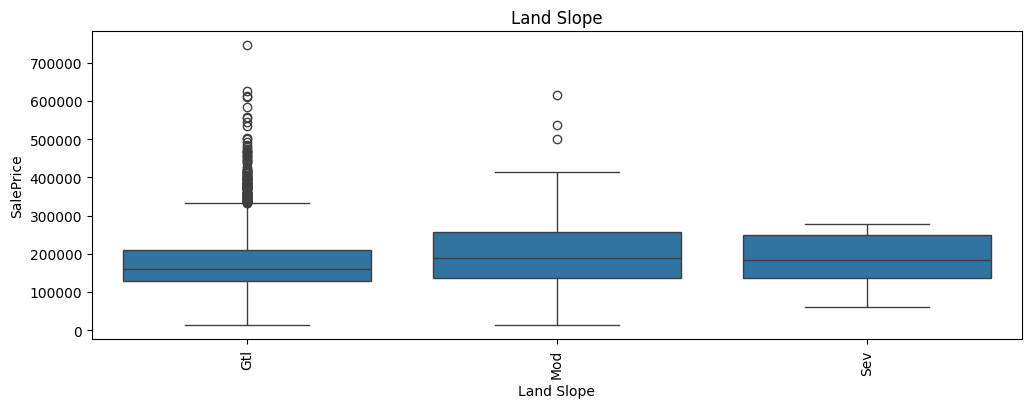

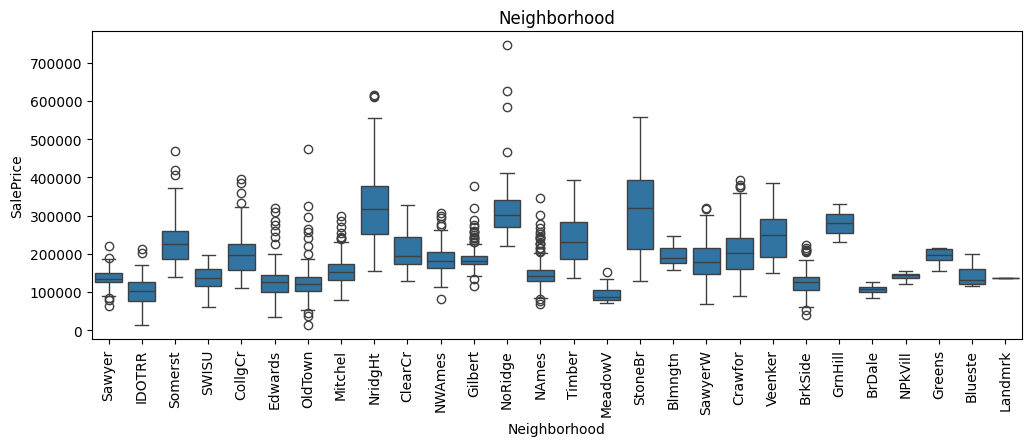

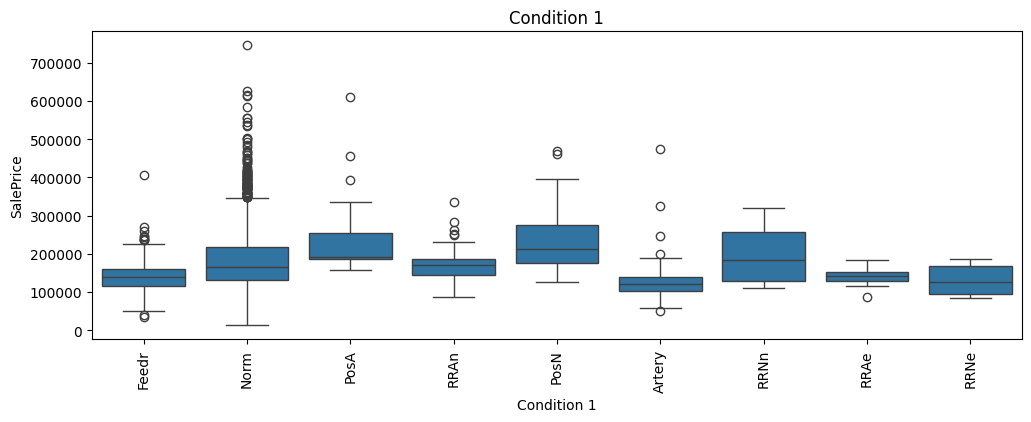

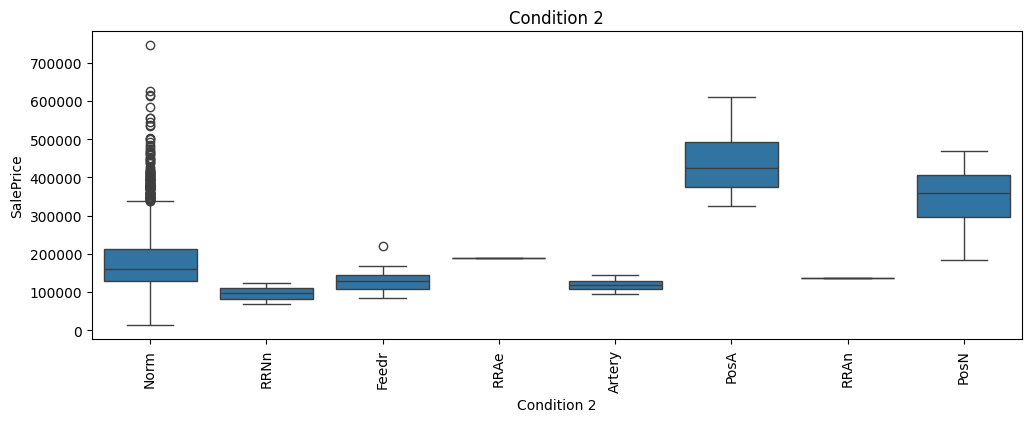

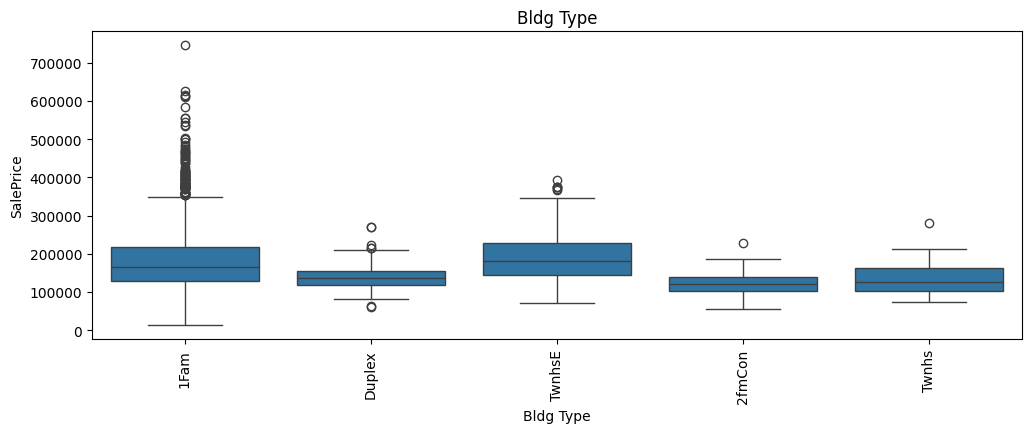

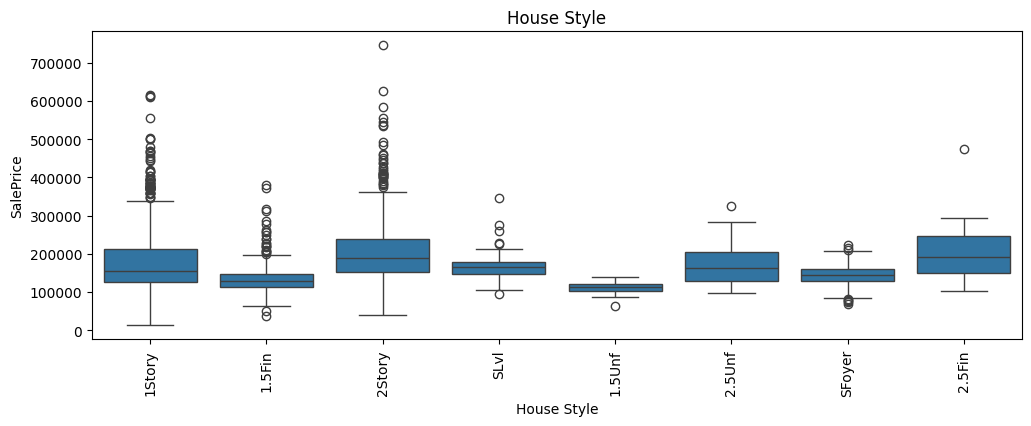

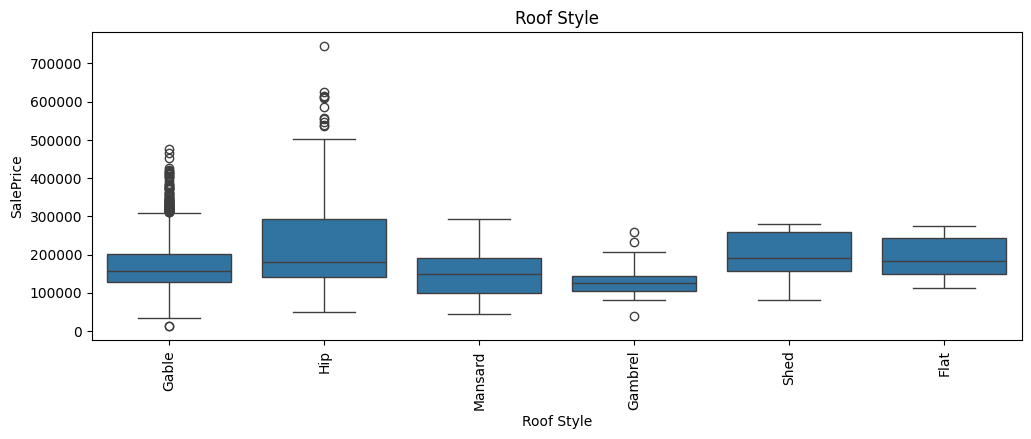

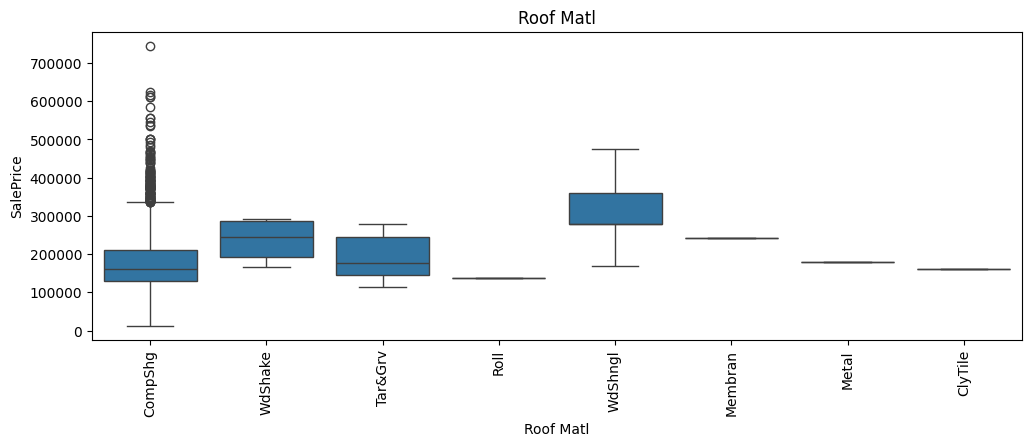

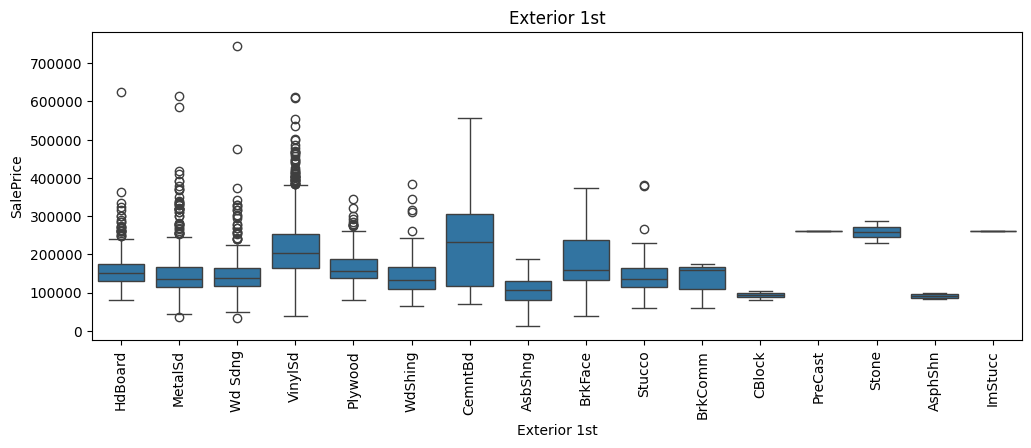

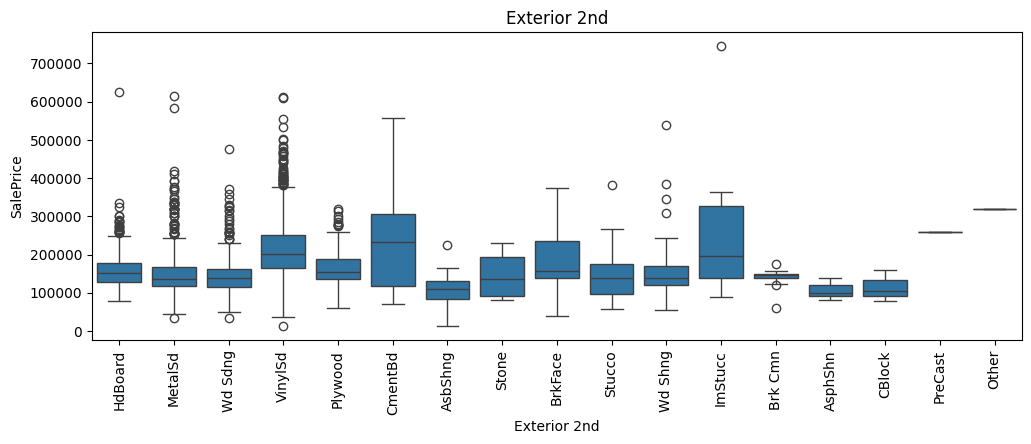

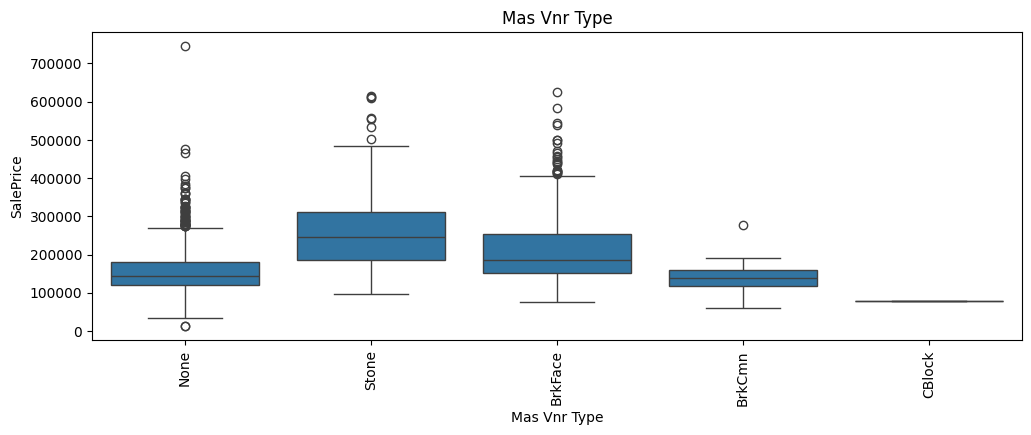

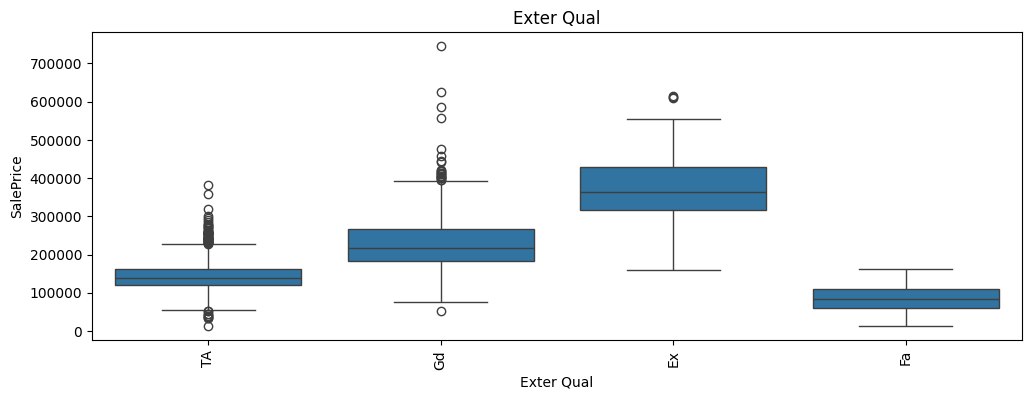

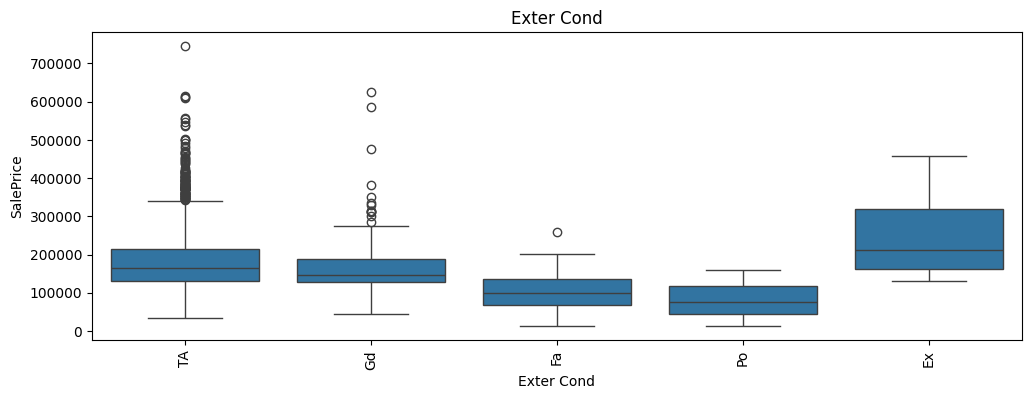

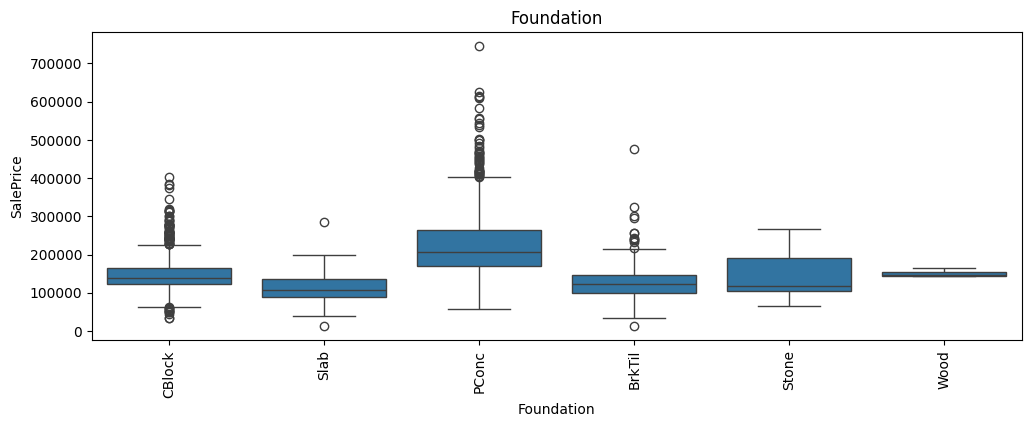

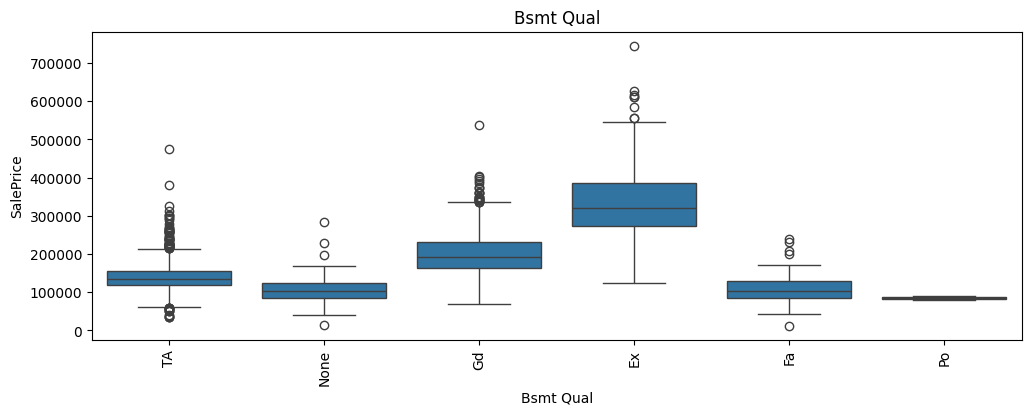

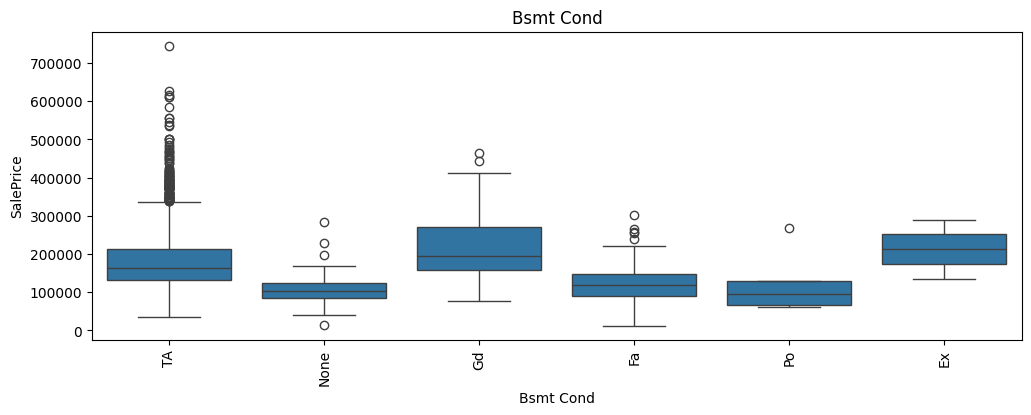

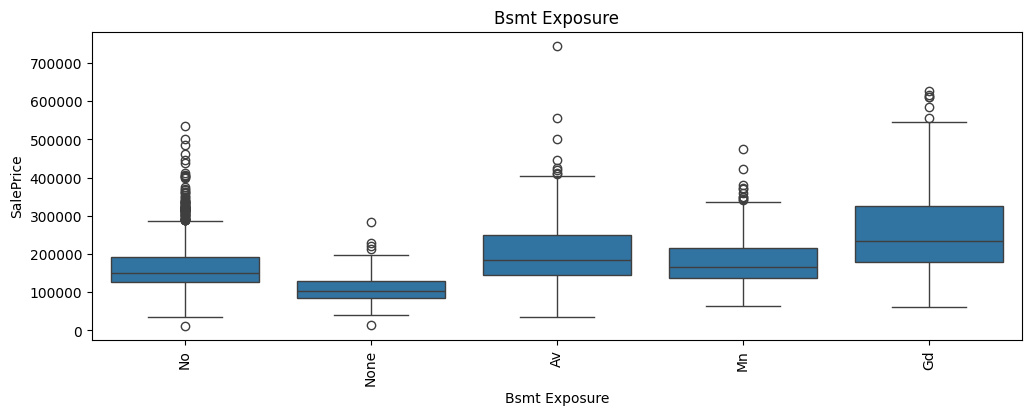

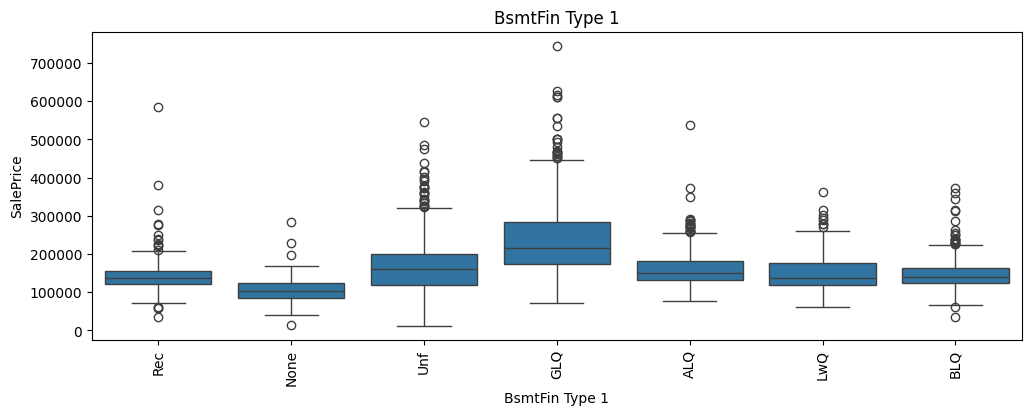

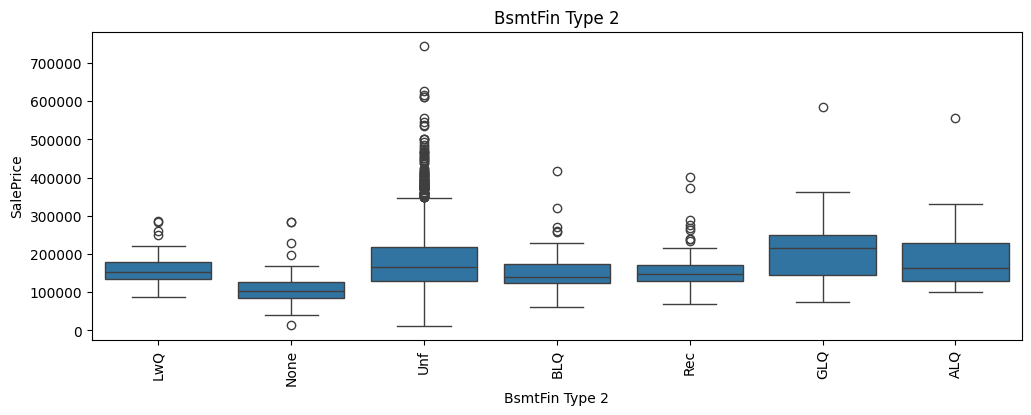

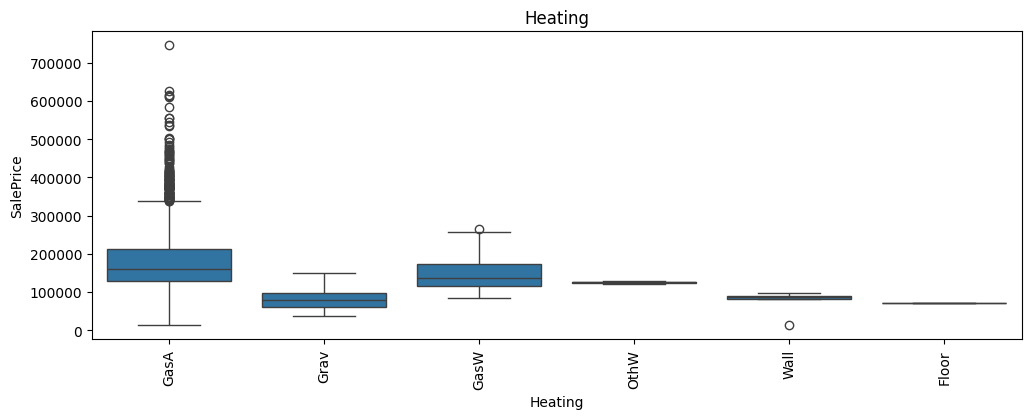

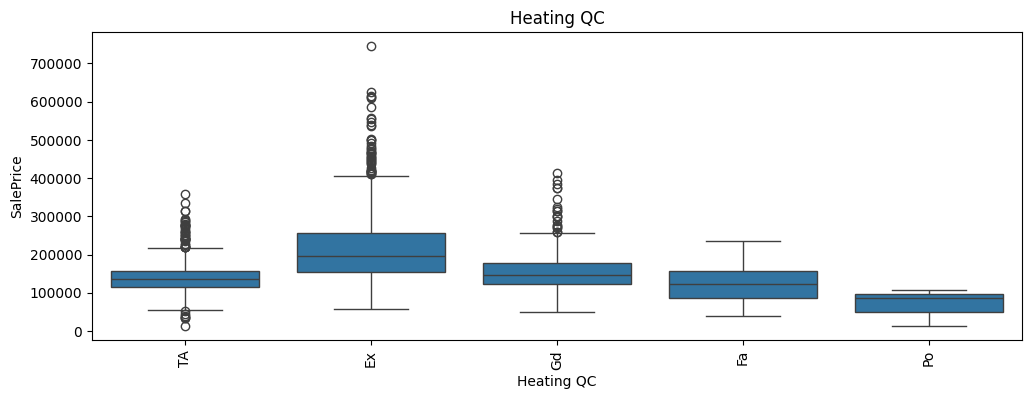

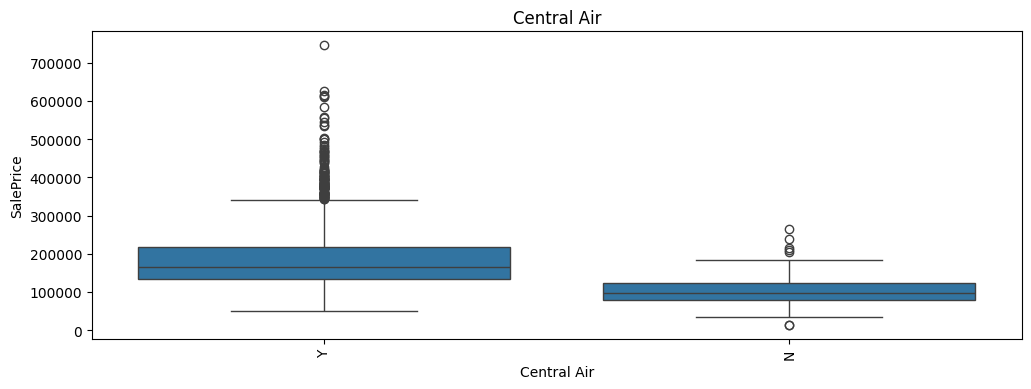

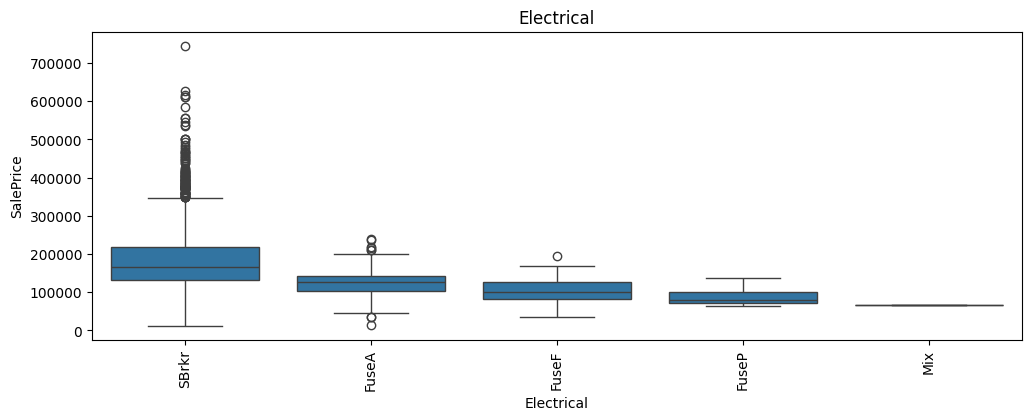

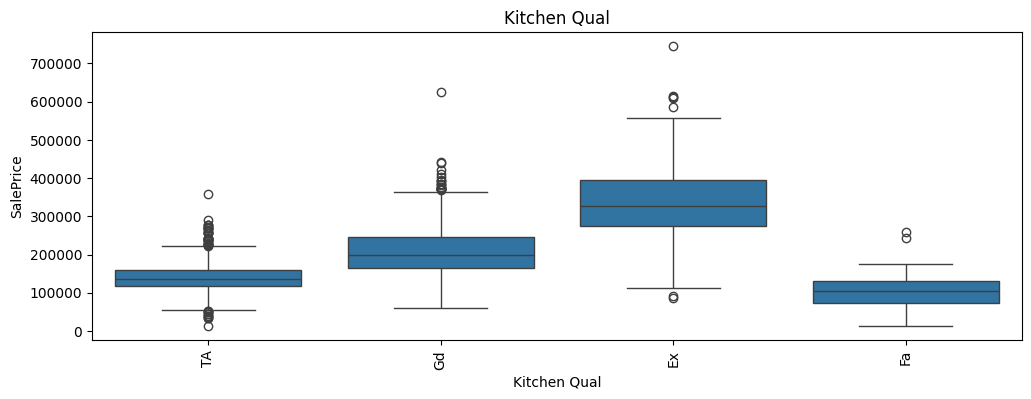

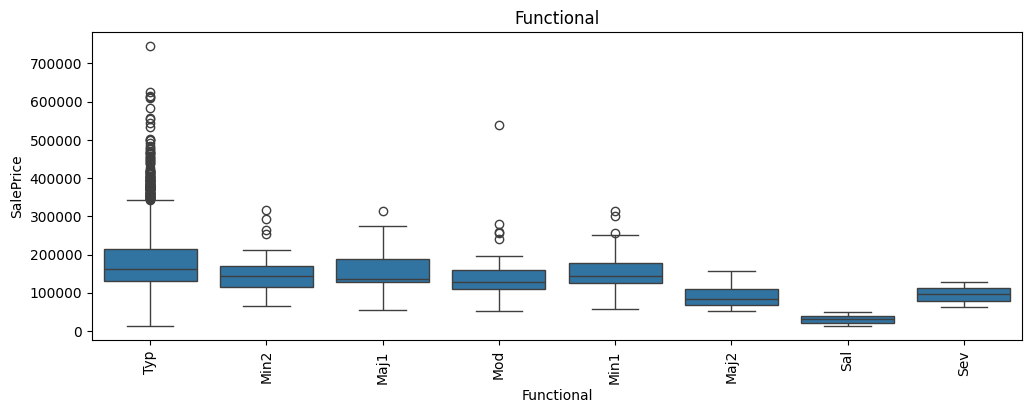

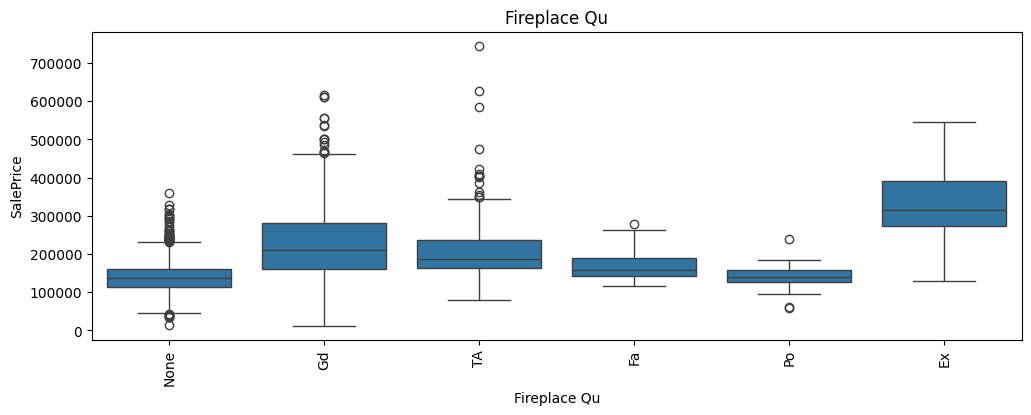

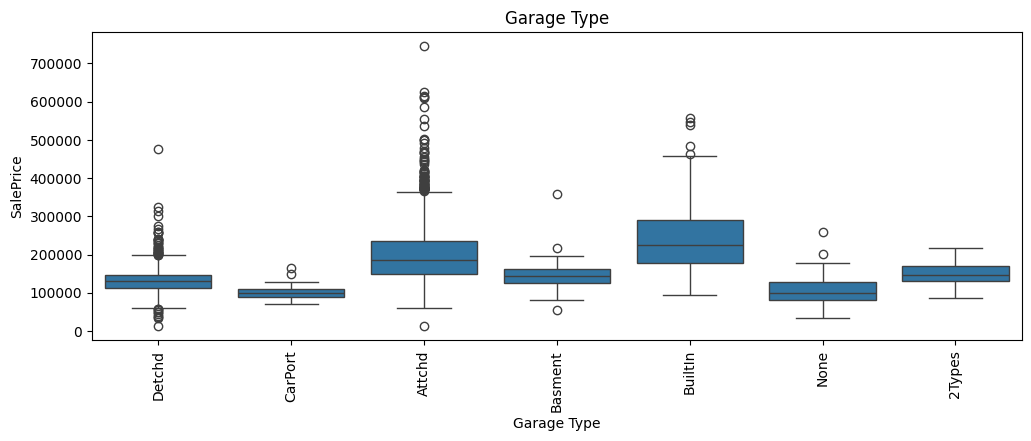

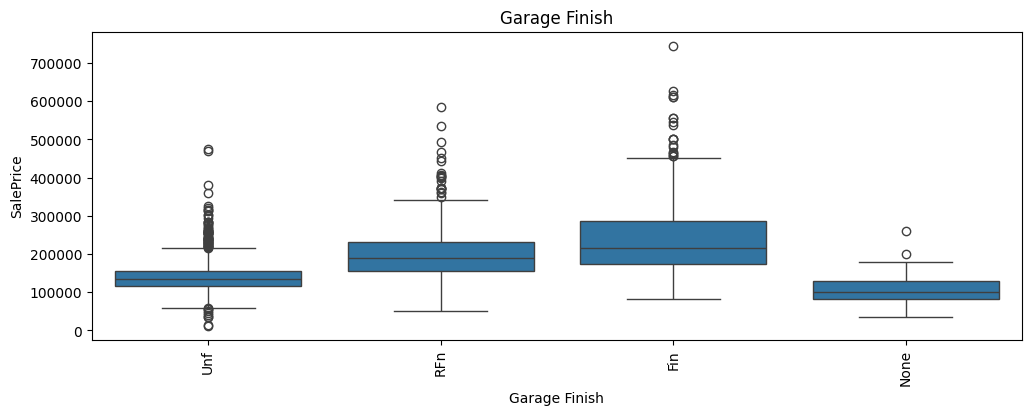

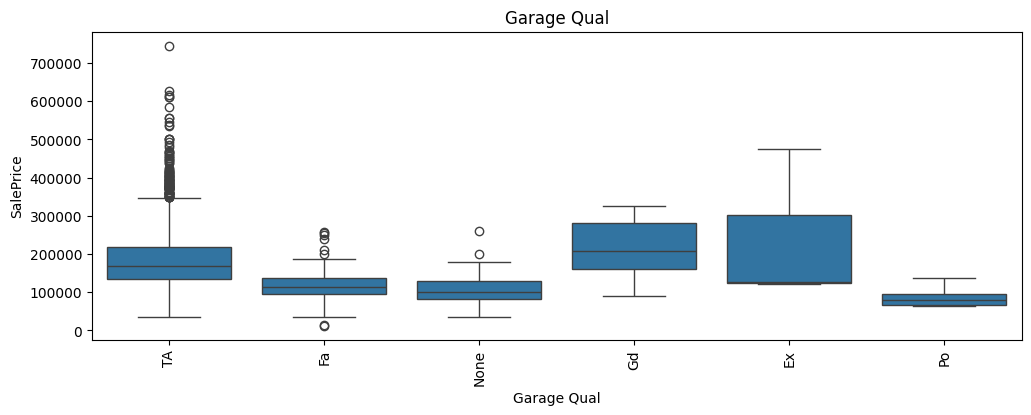

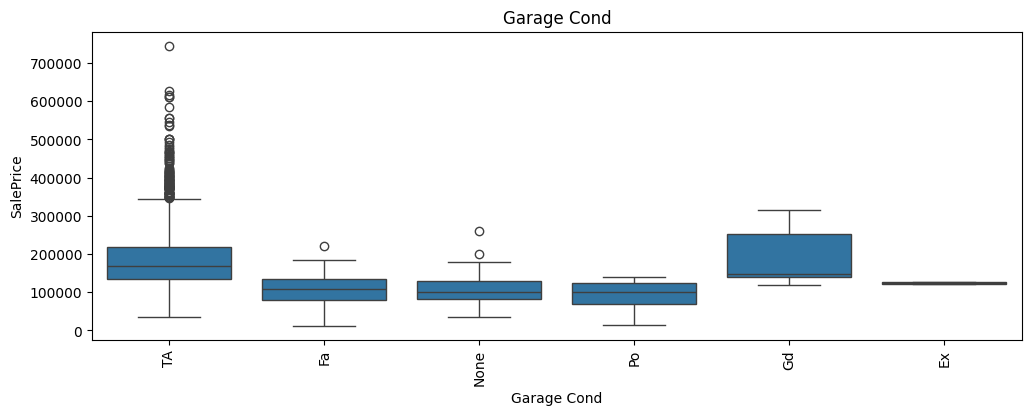

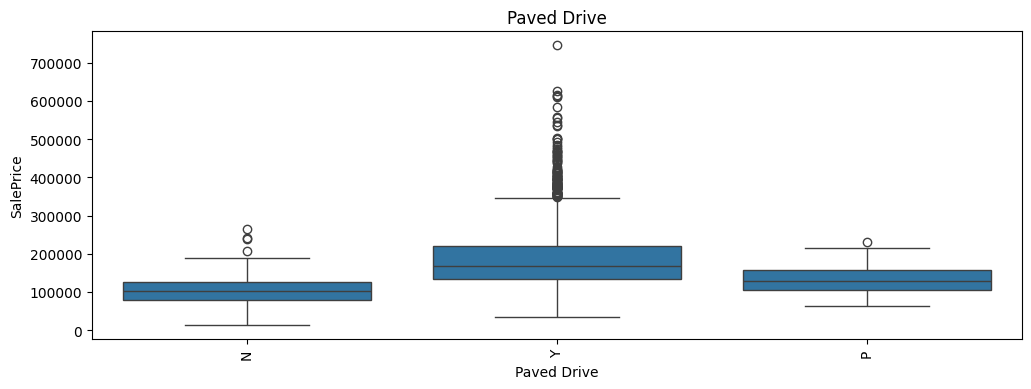

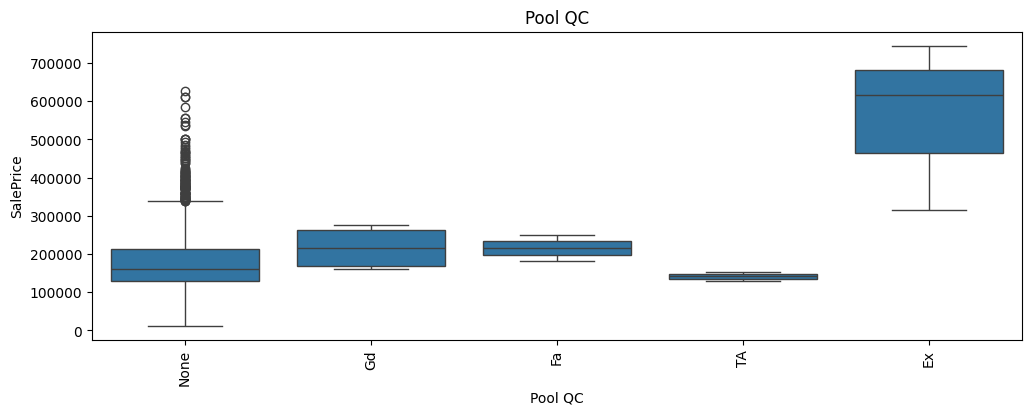

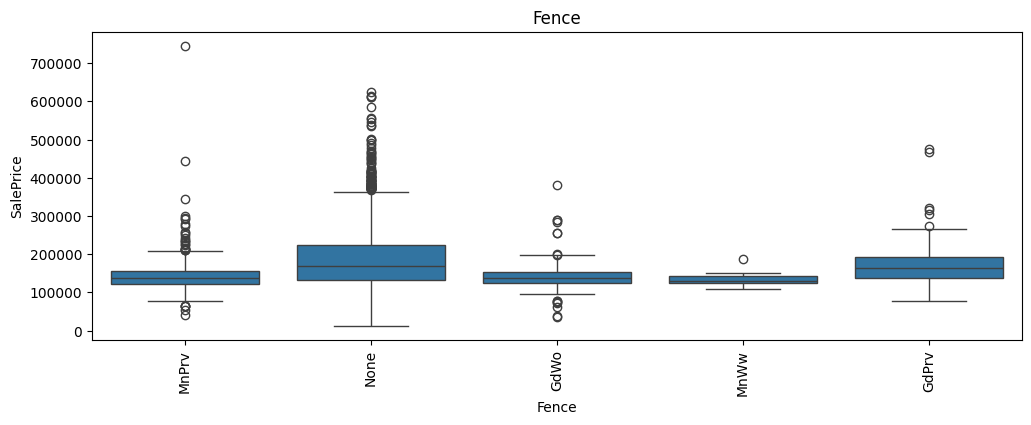

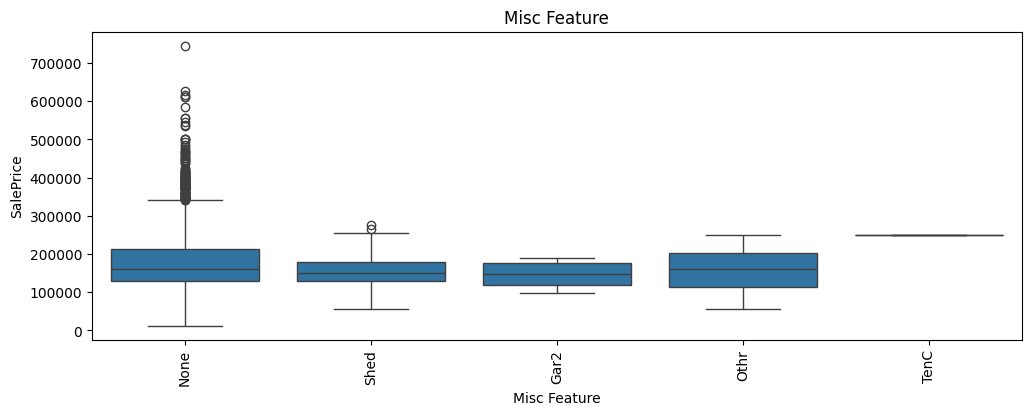

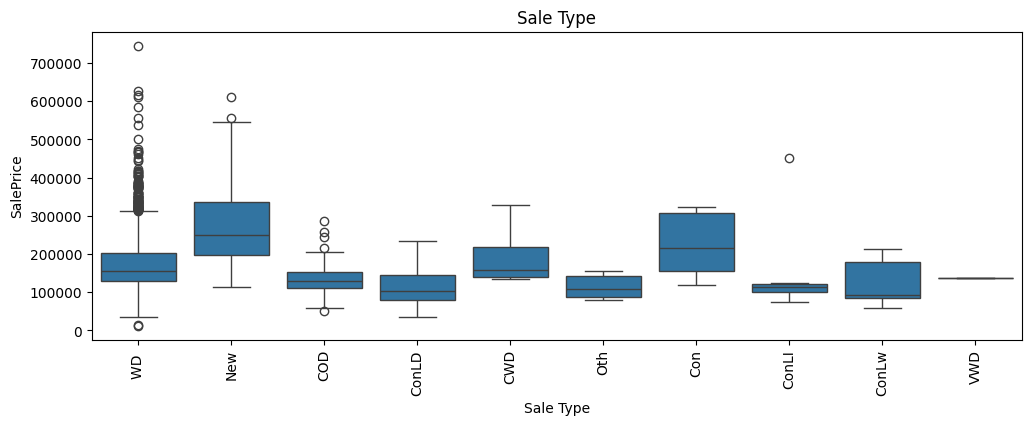

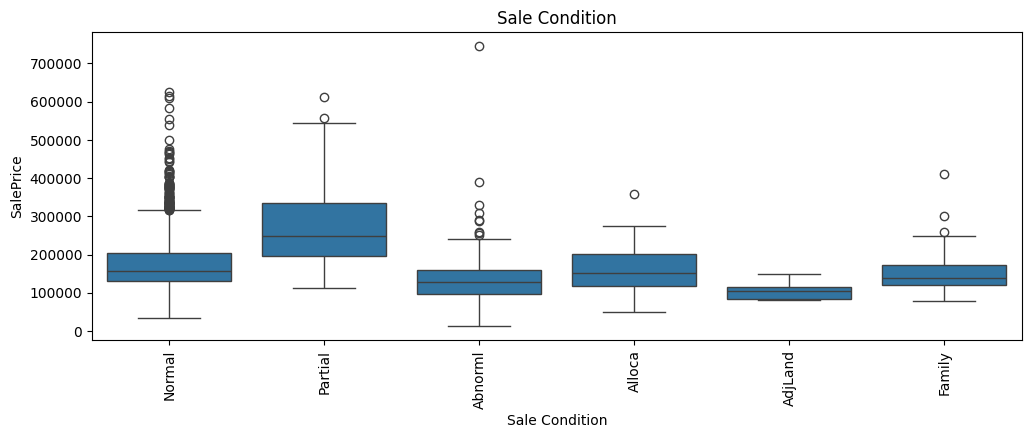

In [22]:
# Same box plot for every text feature
for col in obj_columns:
    plt.figure(figsize=(12, 4))
    sns.boxplot(data=house_df_target_objects, x=col, y='SalePrice')
    plt.xticks(rotation=90)
    plt.title(col)
    plt.show()